# Soal 2 — Data Analysis: *Revenue is growing, but profit is falling*
1. **What happened:** net revenue FY2026 naik **13,2%** (bukan 15%), tetapi gross profit **turun 9,6%**; margin turun dari 15,0% ke 12,0%. Pertumbuhan juga melambat: +24,8% di Sep-Feb, +3,5% di Mar-Agu, dan −9% di tiga bulan terakhir.
2. **Why:** bukan karena biaya supplier (biaya satuan laptop berubah kurang dari 0,2%), melainkan **diskon**. Sejak 1 Sep 2025, channel Online dan tiga sales rep Jawa Timur memberi diskon 20-30% yang membuat penjualan di bawah harga pokok. Di Online, unit naik 9% tetapi revenue datar dan profit turun 55%.
3. **What next/what to do:** revenue Oct-Dec 2026 diperkirakan sekitar **IDR 8,5 miliar** (rentang 7,4-9,3 miliar). Tiga aksi pembatasan diskon bernilai **+IDR 0,4 sampai +0,8 miliar** gross profit per tahun.

## 0. Data and assumptions

Input yang digunakan adalah **cleaned dataset Soal 1** (`sales_transactions_clean.csv`). Masalah yang telah diperbaiki meliputi: 190 transaksi duplikat, 32 baris data test, 982 baris dengan nilai dalam ribuan IDR, format tanggal dan satuan diskon yang beragam, label yang tidak konsisten, serta data biaya yang hilang (telah diestimasi dan ditandai). Asumsi untuk analisis ini adalah:
- **FY** = 1 September hingga 31 Agustus. FY2026 = September 2025–Agustus 2026. Data untuk September 2026 belum lengkap (berakhir pada 15 September), sehingga tidak disertakan dalam perbandingan tahun fiskal (FY).
- **Net revenue** = pendapatan dari transaksi yang berstatus "Selesai" (Completed) ditambah "Dikembalikan" (Returned) (nilai pengembalian dihitung sebagai angka negatif); pesanan yang "Dibatalkan" (Cancelled) dihitung sebagai 0. Laba kotor (Gross profit) = pendapatan bersih − biaya bersih.
- **8 transaksi retail dengan volume 100–400 unit** (senilai Rp4,0 miliar) tidak disertakan karena diduga terjadi kesalahan input (keying errors), sembari menunggu konfirmasi. Jika data tersebut dimasukkan, pertumbuhan tahun fiskal (FY) akan berubah dari +13,2% menjadi +10,7%, namun hal ini tidak mengubah kesimpulan yang ada.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
pd.options.display.float_format = "{:,.2f}".format

SRC = next(p for p in [Path("D:\Penta Sinergi\cleaned_output\sales_transactions_clean.csv"),
                       Path("cleaned_output\sales_transactions_clean.csv"),
                       Path("D:\Penta Sinergi\cleaned_output\sales_transactions_clean.csv")] if p.exists())
raw_clean = pd.read_csv(SRC, parse_dates=["order_date"])
d = raw_clean[raw_clean["include_in_analysis"]].copy()

d["fy"] = np.select([d.order_date < "2025-09-01", d.order_date < "2026-09-01"], ["FY2025", "FY2026"], "Sep-2026 (partial)")
d["ym"] = d["order_date"].dt.to_period("M")
counted = d["status"].isin(["Completed", "Returned"])
d["net_revenue"] = np.where(counted, d["revenue"], 0.0)
d["net_cost"] = np.where(counted, d["cost"], 0.0)
d["gross_profit"] = d["net_revenue"] - d["net_cost"]
d["net_qty"] = np.where(counted, d["qty"], 0)
d["list_value"] = np.where(counted, d["qty"] * d["unit_price"], 0.0)

assert d.groupby("product")["unit_price"].nunique().eq(1).all()          # one list price per product -> clean price/volume split possible
assert ((d.revenue - d.qty * d.unit_price * (1 - d.discount)).abs() < 1).all()
print(f"{len(d):,} lines used | {d.order_date.min().date()} to {d.order_date.max().date()} | source: {SRC.name}")

7,079 lines used | 2024-09-01 to 2026-09-15 | source: sales_transactions_clean.csv


## Task 1 — What happened?

In [2]:
fyd = d[d.fy.isin(["FY2025", "FY2026"])]
def kpis(g):
    comp = g[g.status == "Completed"]
    return pd.Series({"net_revenue": g.net_revenue.sum(), "gross_profit": g.gross_profit.sum(),
                      "margin_pct": g.gross_profit.sum() / g.net_revenue.sum() * 100,
                      "order_lines": len(comp), "units": comp.qty.sum(),
                      "avg_discount_pct": (1 - comp.revenue.sum() / (comp.qty * comp.unit_price).sum()) * 100})
fy_tbl = pd.DataFrame({k: kpis(g) for k, g in fyd.groupby("fy")}).T
fy_tbl.loc["change %"] = (fy_tbl.loc["FY2026"] / fy_tbl.loc["FY2025"] - 1) * 100
fy_tbl.loc["change %", "margin_pct"] = fy_tbl.loc["FY2026", "margin_pct"] - fy_tbl.loc["FY2025", "margin_pct"]   # percentage points
fy_tbl.loc["change %", "avg_discount_pct"] = fy_tbl.loc["FY2026", "avg_discount_pct"] - fy_tbl.loc["FY2025", "avg_discount_pct"]
fy_tbl   # last row: % change; for margin and discount it is percentage points

,net_revenue,gross_profit,margin_pct,order_lines,units,avg_discount_pct
FY2025,"26,123,657,450.00","3,912,426,850.00",14.98,"3,127.00","17,117.00",4.32
FY2026,"29,571,314,700.00","3,537,271,300.00",11.96,"3,466.00","19,334.00",7.11
change %,13.20,-9.59,-3.01,10.84,12.95,2.79


In [3]:
# How it changes over time: fiscal quarters (FQ1 = Sep-Nov ... FQ4 = Jun-Aug)
fyd = fyd.assign(fq="FQ" + ((fyd.order_date.dt.month - 9) % 12 // 3 + 1).astype(str))
q = fyd.groupby(["fq", "fy"])[["net_revenue", "gross_profit"]].sum().unstack("fy")
q_tbl = pd.DataFrame({
    "rev_FY25": q[("net_revenue", "FY2025")], "rev_FY26": q[("net_revenue", "FY2026")],
    "rev_growth_%": (q[("net_revenue", "FY2026")] / q[("net_revenue", "FY2025")] - 1) * 100,
    "margin_FY25_%": q[("gross_profit", "FY2025")] / q[("net_revenue", "FY2025")] * 100,
    "margin_FY26_%": q[("gross_profit", "FY2026")] / q[("net_revenue", "FY2026")] * 100,
    "gp_growth_%": (q[("gross_profit", "FY2026")] / q[("gross_profit", "FY2025")] - 1) * 100})
mon = d.groupby("ym")[["net_revenue", "gross_profit"]].sum()
def yoy(a, b): return (mon.loc[a:b, "net_revenue"].sum() / mon.loc[str(pd.Period(a) - 12):str(pd.Period(b) - 12), "net_revenue"].sum() - 1) * 100
g_h1, g_h2, g_3m, g_12m = yoy("2025-09", "2026-02"), yoy("2026-03", "2026-08"), yoy("2026-06", "2026-08"), yoy("2025-09", "2026-08")
print(f"Revenue growth vs same period last year:  Sep-Feb {g_h1:+.1f}%  |  Mar-Aug {g_h2:+.1f}%  |  last 3 months (Jun-Aug) {g_3m:+.1f}%  |  full FY {g_12m:+.1f}%")
q_tbl

Revenue growth vs same period last year:  Sep-Feb +24.8%  |  Mar-Aug +3.5%  |  last 3 months (Jun-Aug) -9.1%  |  full FY +13.2%


,rev_FY25,rev_FY26,rev_growth_%,margin_FY25_%,margin_FY26_%,gp_growth_%
fq,,,,,,
FQ1,"5,789,129,250.00","7,436,103,250.00",28.45,15.35,13.37,11.91
FQ2,"6,096,549,200.00","7,402,975,600.00",21.43,14.45,11.36,-4.55
FQ3,"6,602,660,750.00","7,788,021,350.00",17.95,15.13,11.13,-13.23
FQ4,"7,635,318,250.00","6,944,214,500.00",-9.05,14.98,12.03,-26.99


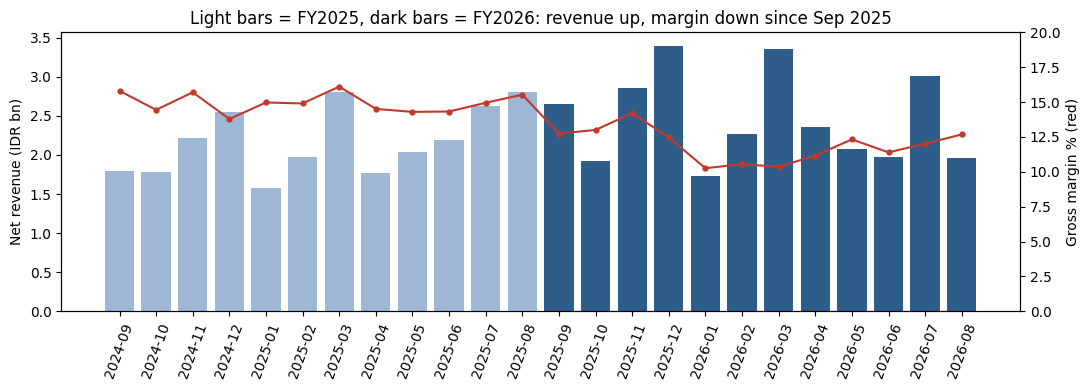

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
m = mon[mon.index < pd.Period("2026-09")].copy(); m["margin"] = m.gross_profit / m.net_revenue * 100
cols = ["#9db7d5" if p < pd.Period("2025-09") else "#2f5d8a" for p in m.index]
ax.bar(m.index.astype(str), m.net_revenue / 1e9, color=cols); ax.set_ylabel("Net revenue (IDR bn)"); ax.tick_params(axis="x", rotation=70)
ax2 = ax.twinx(); ax2.plot(m.index.astype(str), m.margin, color="#c0392b", marker="o", ms=3.5); ax2.set_ylim(0, 20); ax2.set_ylabel("Gross margin % (red)")
ax.set_title("Light bars = FY2025, dark bars = FY2026: revenue up, margin down since Sep 2025")
plt.tight_layout(); plt.show()

**Analisis:** Tahun fiskal 2026 (FY2026) mencatatkan pendapatan sebesar +IDR 3,4 miliar, namun laba kotor justru negatif sebesar -IDR 0,4 miliar. Margin berada di kisaran 14–16% hingga Agustus 2025, kemudian stabil di angka 11–13% pada setiap kuartal fiskal setelahnya. Pertumbuhan yang kuat pada paruh pertama FY2026 kini telah melambat—hal ini menjadi poin penting bagi proyeksi ke depan.

### Penjelasan — Task 1
Tahun fiskal (FY) dihitung 1 September sampai 31 Agustus, sehingga FY2026 = Sep 2025-Agu 2026. Net revenue naik dari IDR 26,1 miliar ke 29,6 miliar, sedangkan gross profit turun dari 3,91 miliar ke 3,54 miliar. Revenue bertambah sekitar IDR 3,4 miliar, tetapi profit berkurang sekitar IDR 0,4 miliar. Margin sekitar 14-16% sampai Agustus 2025, lalu bertahan di 11-13% di setiap kuartal fiskal sesudahnya. Pertumbuhan kuat di semester pertama FY2026 tetapi melambat setelahnya, dan ini penting untuk perkiraan ke depan.

## Task 2 — Why did it happen?

### 2.1 First, test 

In [5]:
# Claim 1: "revenue grew 15%". Which definition gives 15%?
fyr = raw_clean[(raw_clean.include_in_analysis) & (raw_clean.order_date < "2026-09-01")].copy()
fyr["fy"] = np.where(fyr.order_date < "2025-09-01", "FY2025", "FY2026")
def growth(frame, col="revenue"):
    t = frame.groupby("fy")[col].sum(); return (t["FY2026"] / t["FY2025"] - 1) * 100
variants = pd.DataFrame({"revenue growth %": {
    "Sum of every line, incl. Cancelled orders": growth(fyr),
    "Completed lines only (gross sales)": growth(fyr[fyr.status == "Completed"]),
    "Net of returns, Cancelled = 0 (used in this analysis)": growth(d[d.fy.isin(["FY2025", "FY2026"])].rename(columns={}), "net_revenue")}})
canc = fyr[fyr.status == "Cancelled"].groupby("fy")["revenue"].sum() / 1e9
print(f"Cancelled orders still sitting in the revenue column: FY2025 IDR {canc['FY2025']:.2f} bn -> FY2026 IDR {canc['FY2026']:.2f} bn")
variants

Cancelled orders still sitting in the revenue column: FY2025 IDR 0.58 bn -> FY2026 IDR 1.11 bn


,revenue growth %
Completed lines only (gross sales),13.17
"Net of returns, Cancelled = 0 (used in this analysis)",13.20
"Sum of every line, incl. Cancelled orders",14.90


In [6]:
# Claim 2: "profit fell because laptop supplier costs went up". Check unit cost per laptop (median, completed lines)
lap = d[(d.category == "Laptop") & (d.status == "Completed") & d.fy.isin(["FY2025", "FY2026"])].copy()
lap["unit_cost"] = lap.cost / lap.qty
lap_cost = lap.groupby(["product", "fy"])["unit_cost"].median().unstack("fy")
lap_cost["change_%"] = (lap_cost["FY2026"] / lap_cost["FY2025"] - 1) * 100
allp = d[(d.status == "Completed") & d.fy.isin(["FY2025", "FY2026"])].assign(uc=lambda x: x.cost / x.qty)
uc_all = allp.groupby(["product", "fy"])["uc"].median().unstack("fy"); uc_all = (uc_all["FY2026"] / uc_all["FY2025"] - 1) * 100
print(f"Unit cost change across ALL 15 products: min {uc_all.min():+.2f}%, max {uc_all.max():+.2f}%")
lap_cost

Unit cost change across ALL 15 products: min -0.28%, max +0.47%


fy,FY2025,FY2026,change_%
product,,,
Laptop Axio 14,"7,592,500.00","7,597,700.00",0.07
Laptop Axio Pro 15,"11,631,000.00","11,651,900.00",0.18
Laptop Veno 13,"5,551,600.00","5,548,900.00",-0.05


- **"Revenue +15%"** hanya diperoleh dengan menjumlahkan *setiap* baris, **termasuk pesanan yang dibatalkan**, yang nilainya hampir meningkat dua kali lipat (dari Rp0,6 miliar menjadi Rp1,1 miliar). Pertumbuhannya adalah **+13,2%**.
- Klaim bahwa **"biaya laptop meningkat"** **tidak terbukti**: biaya per unit untuk setiap model laptop hanya berubah sebesar 0,2% atau kurang, dan tidak ada produk dalam jajaran tersebut yang mengalami perubahan lebih dari 0,5%. Jadi, kenaikan biaya bukanlah penyebab penurunan profit.

### 2.2 Where did the gross profit go? A price / volume / cost bridge (FY2025 → FY2026)

In [7]:
# Exact decomposition per product: GP = Q x (list price x (1 - discount%) - unit cost); list prices are constant per product.
f = d[d.fy.isin(["FY2025", "FY2026"])].groupby(["category", "product", "fy"])[["net_qty", "net_revenue", "net_cost", "list_value"]].sum().unstack("fy")
Q1, Q2 = f[("net_qty", "FY2025")], f[("net_qty", "FY2026")]
R1, R2 = f[("net_revenue", "FY2025")], f[("net_revenue", "FY2026")]
C1, C2 = f[("net_cost", "FY2025")], f[("net_cost", "FY2026")]
L1, L2 = f[("list_value", "FY2025")], f[("list_value", "FY2026")]
dis1, dis2 = 1 - R1 / L1, 1 - R2 / L2
bridge = pd.DataFrame({
    "volume_and_mix": (Q2 - Q1) * (R1 - C1) / Q1,           # more units at last year's unit profit
    "discounts": -(dis2 - dis1) * L2,                         # deeper discounts on this year's list value
    "unit_cost": -(C2 / Q2 - C1 / Q1) * Q2})                  # change in unit cost on this year's units
bridge["total_change"] = bridge.sum(axis=1)
assert np.allclose(bridge["total_change"], (R2 - C2) - (R1 - C1))          # the bridge adds up exactly
by_cat = bridge.groupby(level="category").sum()
tot = bridge.sum()
gp25, gp26 = (R1 - C1).sum(), (R2 - C2).sum()
print(f"GP FY2025 {gp25:,.0f}  ->  volume/mix {tot.volume_and_mix:+,.0f}  discounts {tot.discounts:+,.0f}  unit cost {tot.unit_cost:+,.0f}  ->  GP FY2026 {gp26:,.0f}")
by_cat.assign(total_change=by_cat.sum(axis=1)).sort_values("total_change")

GP FY2025 3,912,426,850  ->  volume/mix +536,294,927  discounts -898,337,373  unit cost -13,113,104  ->  GP FY2026 3,537,271,300


,volume_and_mix,discounts,unit_cost,total_change
category,,,,
Laptop,"217,109,094.47","-473,687,783.61","2,597,789.14","-507,961,800.00"
Smartphone,"28,378,686.04","-222,029,879.02","-1,653,757.03","-390,609,900.00"
Networking,"33,210,378.43","-54,563,151.98","-3,213,576.45","-49,132,700.00"
Aksesoris,"25,348,520.47","-39,841,496.52","764,226.05","-27,457,500.00"
Printer & Tinta,"75,638,223.07","-79,745,371.44","-6,794,051.62","-21,802,400.00"
Peralatan Kantor,"156,610,024.46","-28,469,690.79","-4,813,733.67","246,653,200.00"


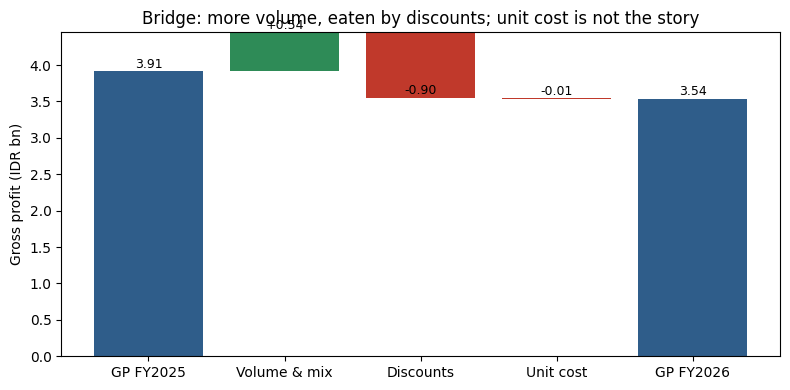

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
steps = [("GP FY2025", gp25), ("Volume & mix", tot.volume_and_mix), ("Discounts", tot.discounts), ("Unit cost", tot.unit_cost), ("GP FY2026", gp26)]
run = 0
for i, (lbl, v) in enumerate(steps):
    if i in (0, len(steps) - 1):
        ax.bar(lbl, v / 1e9, color="#2f5d8a"); run = v if i == 0 else run
    else:
        ax.bar(lbl, v / 1e9, bottom=run / 1e9, color="#2e8b57" if v >= 0 else "#c0392b"); run += v
    ax.text(i, (v if i in (0, 4) else run) / 1e9 + 0.05, f"{v / 1e9:+.2f}" if i not in (0, 4) else f"{v / 1e9:.2f}", ha="center", fontsize=9)
ax.set_ylabel("Gross profit (IDR bn)"); ax.set_title("Bridge: more volume, eaten by discounts; unit cost is not the story")
plt.tight_layout(); plt.show()

**Analisis:** Penjualan unit yang lebih banyak *seharusnya* menambah laba sekitar **+IDR 0,5 miliar**. Diskon yang lebih besar justru mengurangi laba sekitar **IDR 0,9 miliar**. Biaya per unit hampir tidak memberikan dampak apa pun (−IDR 0,01 miliar). Laptop dan ponsel pintar menjadi penyumbang terbesar atas penurunan ini, karena margin keuntungannya tipis, pemberian diskon, meskipun dalam jumlah yang sama langsung menghapus margin tersebut.

### 2.3 Where do the discounts happen, and did they buy growth?

In [9]:
fy26 = d[d.fy.isin(["FY2025", "FY2026"])].copy()
fy26["segment"] = np.where(fy26.channel == "Online", "Online (all regions)", np.where(fy26.region == "Jawa Timur", "Offline - Jawa Timur", "Offline - other regions"))
seg = fy26.groupby(["segment", "fy"])[["net_revenue", "gross_profit"]].sum().unstack("fy")
comp_ = fy26[fy26.status == "Completed"]
cs = comp_.assign(lv=comp_.qty * comp_.unit_price).groupby(["segment", "fy"])[["revenue", "lv"]].sum()
disc = ((1 - cs["revenue"] / cs["lv"]) * 100).unstack("fy")
units = comp_.groupby(["segment", "fy"])["qty"].sum().unstack("fy")
seg_tbl = pd.DataFrame({
    "revenue_change_%": (seg[("net_revenue", "FY2026")] / seg[("net_revenue", "FY2025")] - 1) * 100,
    "revenue_change_IDR": seg[("net_revenue", "FY2026")] - seg[("net_revenue", "FY2025")],
    "gp_change_%": (seg[("gross_profit", "FY2026")] / seg[("gross_profit", "FY2025")] - 1) * 100,
    "gp_change_IDR": seg[("gross_profit", "FY2026")] - seg[("gross_profit", "FY2025")],
    "margin_FY25_%": seg[("gross_profit", "FY2025")] / seg[("net_revenue", "FY2025")] * 100,
    "margin_FY26_%": seg[("gross_profit", "FY2026")] / seg[("net_revenue", "FY2026")] * 100,
    "avg_discount_FY25_%": disc["FY2025"], "avg_discount_FY26_%": disc["FY2026"], "units_change_%": (units["FY2026"] / units["FY2025"] - 1) * 100})
seg_tbl

,revenue_change_%,revenue_change_IDR,gp_change_%,gp_change_IDR,margin_FY25_%,margin_FY26_%,avg_discount_FY25_%,avg_discount_FY26_%,units_change_%
segment,,,,,,,,,
Offline - Jawa Timur,25.45,"673,836,250.00",-11.50,"-45,952,000.00",15.09,10.64,2.92,9.74,34.88
Offline - other regions,20.96,"2,828,625,900.00",20.42,"434,250,100.00",15.76,15.69,3.05,2.89,10.86
Online (all regions),-0.55,"-54,804,900.00",-55.08,"-763,453,650.00",13.89,6.27,6.36,12.46,9.13


In [10]:
# Margin by discount depth (completed lines, FY2026 and FY2025 together)
c = d[(d.status == "Completed") & d.fy.isin(["FY2025", "FY2026"])].copy(); c["gp"] = c.revenue - c.cost
c["band"] = pd.cut(c.discount, [-0.001, 0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30], labels=["0%", "5%", "8-10%", "12-15%", "20%", "25%", "30%"])
bands = c.groupby("band", observed=True).agg(lines=("revenue", "size"), revenue=("revenue", "sum"), gross_profit=("gp", "sum"))
bands["margin_pct"] = bands.gross_profit / bands.revenue * 100
bands["sold_below_cost"] = c.assign(neg=c.gp < 0).groupby("band", observed=True)["neg"].sum()
print("first line with discount >= 20%:", c.loc[c.discount >= 0.20, "order_date"].min().date(), "| max discount before:", c.loc[c.order_date < "2025-09-01", "discount"].max())
off = c[(c.order_date >= "2025-09-01") & (c.channel == "Offline") & (c.discount >= 0.20)]
print("offline reps with any >=20% line:", sorted(off.sales_rep.unique()), "| their regions:", off.region.unique().tolist())
bands

first line with discount >= 20%: 2025-09-01 | max discount before: 0.15
offline reps with any >=20% line: ['SR07', 'SR08', 'SR09'] | their regions: ['Jawa Timur']


,lines,revenue,gross_profit,margin_pct,sold_below_cost
band,,,,,
0%,2897,"25,430,155,000.00","4,478,515,000.00",17.61,0
5%,1873,"15,141,641,500.00","2,038,448,550.00",13.46,0
8-10%,1057,"10,040,149,500.00","1,209,117,700.00",12.04,45
12-15%,193,"2,461,047,900.00","252,364,650.00",10.25,63
20%,188,"1,208,656,000.00","-16,731,900.00",-1.38,74
25%,200,"1,314,832,500.00","-139,948,550.00",-10.64,90
30%,185,"1,171,656,500.00","-215,794,450.00",-18.42,97


**Analisis:**
- **Online** (promosi menyeluruh, rata-rata diskon meningkat dari 6,4% menjadi 12,5%): volume unit naik 9%, namun revenue **stagnan (−0,5%)** dan gross profit turun **55%**; margin menyusut dari 13,9% menjadi 6,3%. Promosi tersebut memang meningkatkan volume, tetapi pada tingkat harga yang justru meniadakan keuntungan.
- **Offline, lima wilayah lainnya** (tanpa diskon besar-besaran, rata-rata ~3%): revenue **naik 21%**, gross profit **naik 20%**, dengan margin stabil di angka 15,7%. Ini adalah mesin pertumbuhan yang sesungguhnya: menyumbang Rp2,8 miliar dari total pertumbuhan pendapatan sebesar Rp3,4 miliar.
- **Offline Jawa Timur** (khusus perwakilan SR07–SR09): revenue naik 25%, namun gross profit **turun 11,5%**. Terjadi pertumbuhan yang didorong oleh diskon, tetapi tidak menghasilkan profit.
- Margin terus menurun seiring dengan semakin besarnya diskon dan bahkan menjadi **negatif pada tingkat diskon 20%** (masing-masing −1,4%, −10,6%, dan −18,4% untuk tingkat diskon 20%, 25%, dan 30%). Pemberian diskon ≥20% pertama kali tercatat pada **1 September 2025**; sebelumnya, tingkat diskon terbesar yang pernah diberikan adalah 15%.

**Verdict on the three statements**

| Statement | Verdict | Evidence |
|---|---|---|
| Head of Sales: revenue +15 % | Overstated | Cancelled orders are counted; true net growth is +13.2 % |
| Head of Sales: laptop supplier costs rose, outside our control | **Not supported** | Laptop unit cost +0.07 %, +0.18 %, −0.05 %; the profit loss is discounting, which *is* in our control |
| Marketing: promotions drove growth, do more | **Not supported** | Online (promoted): revenue flat, profit −55 %. Growth came from offline regions without deep discounts |

### Penjelasan — Task 2
**Menguji pernyataan di rapat:**
- *"Revenue naik 15%"*: angka ini hanya muncul jika **order yang dibatalkan ikut dijumlahkan** (nilainya hampir dua kali lipat, dari IDR 0,6 miliar ke 1,1 miliar). Dihitung dengan benar, pertumbuhannya +13,2%.
- *"Biaya supplier laptop naik"*: **tidak didukung data**. Biaya satuan tiga model laptop berubah +0,07%, +0,18%, dan −0,05%.

**Jembatan profit** (FY2025 ke FY2026): tambahan volume seharusnya menambah profit sekitar IDR 0,5 miliar, tetapi diskon yang makin dalam mengurangi sekitar IDR 0,9 miliar, dan biaya satuan hampir nol. Laptop dan smartphone paling terdampak karena marginnya tipis sehingga diskon yang sama langsung menghabiskannya.

**Di mana pertumbuhan dan kerugian terjadi:** Online (diskon rata-rata 6,4% naik ke 12,5%): unit +9% tetapi revenue −0,5% dan profit −55%. Offline di lima region lain (diskon sekitar 3%): revenue +21% dan profit +20% dengan margin stabil 15,7%; inilah mesin pertumbuhan yang sebenarnya. Offline Jawa Timur (SR07-SR09): revenue +25% tetapi profit −11,5%. Margin menjadi negatif mulai diskon 20%, dan diskon sebesar itu pertama kali muncul pada 1 Sep 2025.

**Kesimpulan:** klaim "promosi mendorong pertumbuhan" tidak didukung data, dan penurunan profit bisa dikendalikan oleh perusahaan karena berasal dari kebijakan diskon.

## Task 3 — What is likely to happen next?
**Method (simple on purpose).** Revenue sangat dipengaruhi oleh musim (dengan puncak pada bulan Maret, Juli, dan Desember), sehingga saya menggunakan data **bulan yang sama pada tahun sebelumnya dan menerapkan tingkat pertumbuhan year-on-year**. Tingkat pertumbuhan merupakan asumsi kunci yang telah mengalami perubahan signifikan: +24,8% pada periode September–Februari, +3,5% pada periode Maret–Agustus, dan −9,1% pada periode Juni–Agustus. Oleh karena itu, saya menyajikan tiga skenario beserta pengujian retrospektif (*back-test*). Periode prakiraan mencakup bulan **Oktober–Desember 2026**, yakni bulan-bulan penuh pertama setelah berakhirnya ketersediaan data (15 September 2026).

In [11]:
base_months = ["2025-10", "2025-11", "2025-12"]
base = mon.loc[base_months, "net_revenue"]
scen = {"Low (last 3 months: Jun-Aug)": g_3m, "Base (last 6 months: Mar-Aug)": g_h2, "High (full FY2026)": g_12m}
fc = pd.DataFrame({name: base.values * (1 + g / 100) for name, g in scen.items()}, index=["2026-10", "2026-11", "2026-12"])
fc.loc["Total Oct-Dec 2026"] = fc.sum()
fc.loc["growth rate used, %"] = list(scen.values())
print("Oct-Dec 2025 actual:", f"{base.sum():,.0f}")

# Back-test the method: at two past cut-off dates, use the trailing-6-month growth rate to forecast the next 3 months
def backtest(origin_end, fcs):
    s = str(pd.Period(origin_end) - 5)
    g = yoy(s, origin_end) / 100
    f_ = sum(mon.loc[str(pd.Period(m) - 12), "net_revenue"] * (1 + g) for m in fcs); a_ = mon.loc[fcs, "net_revenue"].sum()
    return {"cut-off": origin_end, "growth used %": g * 100, "forecast": f_, "actual": a_, "error %": (f_ / a_ - 1) * 100}
bt = pd.DataFrame([backtest("2026-02", ["2026-03", "2026-04", "2026-05"]), backtest("2026-05", ["2026-06", "2026-07", "2026-08"])])
print(bt.round(1).to_string(index=False))
t6_margin = mon.loc["2026-03":"2026-08", "gross_profit"].sum() / mon.loc["2026-03":"2026-08", "net_revenue"].sum() * 100
gp_fc = fc.loc["Total Oct-Dec 2026"] * t6_margin / 100
print(f"\nGross profit if the last-6-month margin ({t6_margin:.1f}%) persists:", gp_fc.round(0).to_dict())
fc

Oct-Dec 2025 actual: 8,177,029,800
cut-off  growth used %         forecast           actual  error %
2026-02          24.80 8,243,316,012.70 7,788,021,350.00     5.80
2026-05          19.60 9,133,489,146.50 6,944,214,500.00    31.50

Gross profit if the last-6-month margin (11.6%) persists: {'Low (last 3 months: Jun-Aug)': 859124991.0, 'Base (last 6 months: Mar-Aug)': 977418790.0, 'High (full FY2026)': 1069293733.0}


,Low (last 3 months: Jun-Aug),Base (last 6 months: Mar-Aug),High (full FY2026)
2026-10,"1,749,184,725.98","1,990,031,760.31","2,177,089,812.31"
2026-11,"2,597,642,965.37","2,955,315,082.65","3,233,107,373.93"
2026-12,"3,090,065,840.12","3,515,540,166.78","3,845,992,227.12"
Total Oct-Dec 2026,"7,436,893,531.46","8,460,887,009.74","9,256,189,413.37"
"growth rate used, %",-9.05,3.47,13.20


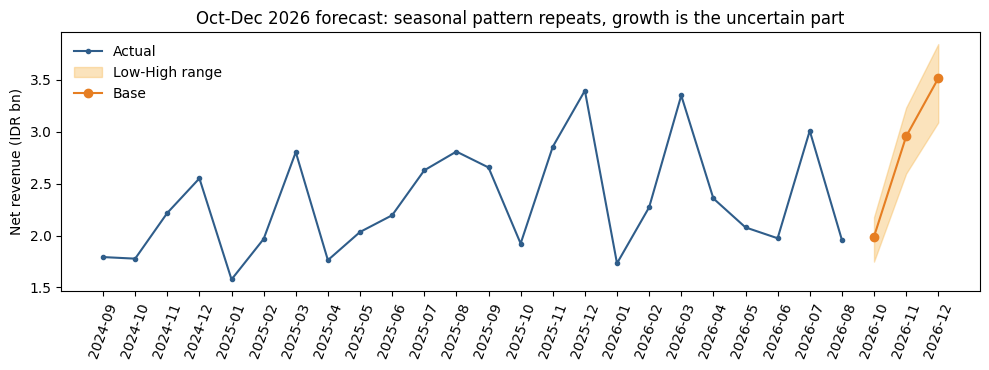

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.8))
act = mon[mon.index <= pd.Period("2026-08")]
ax.plot(act.index.astype(str), act.net_revenue / 1e9, color="#2f5d8a", marker="o", ms=3, label="Actual")
x = ["2026-10", "2026-11", "2026-12"]
ax.fill_between(x, fc.iloc[:3, 0] / 1e9, fc.iloc[:3, 2] / 1e9, color="#f5b041", alpha=0.35, label="Low-High range")
ax.plot(x, fc.iloc[:3, 1] / 1e9, color="#e67e22", marker="o", label="Base")
ax.set_ylabel("Net revenue (IDR bn)"); ax.tick_params(axis="x", rotation=70); ax.legend(frameon=False); ax.set_title("Oct-Dec 2026 forecast: seasonal pattern repeats, growth is the uncertain part")
plt.tight_layout(); plt.show()

**Interpretasi:** Skenario dasar menunjukkan angka **sekitar Rp8,5 miliar untuk periode Oktober–Desember 2026** (+3,5% dibandingkan tahun sebelumnya), dengan kisaran yang mungkin terjadi antara **Rp7,4 miliar hingga Rp9,3 miliar**. Dengan margin saat ini (~11,6%), laba kotor yang dihasilkan hanya **sekitar Rp1,0 miliar**. Berhati-hatilah dengan skenario optimis (angka tertinggi): dalam pengujian retrospektif (*back-test*), tingkat pertumbuhan yang diambil dari enam bulan sebelumnya menghasilkan prakiraan yang terlalu tinggi untuk periode Juni–Agustus—dengan selisih sekitar 31%—karena pertumbuhan saat itu sebenarnya sudah melambat. Risiko serupa juga berlaku untuk saat ini. **Plan on the low-to-base case.**

*Asumsi dan batasan:* data historis hanya mencakup dua tahun (satu siklus musiman sebagai acuan), pendapatan bulanan bersifat fluktuatif (satu pesanan dalam jumlah besar dapat memengaruhi angka bulanan secara signifikan), ini mengasumsikan tidak ada perubahan kebijakan harga, tidak ada promosi baru, dan tidak ada guncangan pasokan. Pengujian retrospektif menunjukkan tingkat kesalahan berkisar antara 6% hingga 32% untuk total periode tiga bulan, oleh karena itu jadikan kisaran angka tersebut, bukan satu angka tunggal, sebagai jawaban yang tepat.

### Penjelasan — Task 3
Metodenya sengaja sederhana: karena revenue sangat musiman (puncak di Maret, Juli, dan Desember), saya memakai **bulan yang sama tahun lalu dikalikan laju pertumbuhan year-on-year**. Asumsi kuncinya adalah laju pertumbuhan, yang berubah drastis, jadi ada tiga skenario: rendah (−9,1%, tiga bulan terakhir), dasar (+3,5%, enam bulan terakhir), dan tinggi (+13,2%, setahun penuh). Hasilnya untuk Oct-Dec 2026: sekitar **IDR 7,4 / 8,5 / 9,3 miliar**; pada margin saat ini (sekitar 11,6%) gross profit hanya sekitar IDR 1,0 miliar.

Uji mundur menunjukkan galat perkiraan tiga bulan sebesar 5,8% dan 31,5%; galat besar terjadi karena pertumbuhan sedang melambat. Karena itu **gunakan skenario rendah sampai dasar untuk perencanaan**. Keterbatasan: hanya dua tahun data (satu siklus musiman) dan perkiraan mengandaikan tidak ada perubahan kebijakan harga.

## Task 4 — What should we do?

Tiga actions, yang dihitung berdasarkan **transaksi Tahun Fiskal 2026** ("bagaimana jika aturan ini diterapkan tahun lalu"). Setiap tindakan hanya memengaruhi lini produk yang menjadi sasarannya, tingkat pengembalian (retur) dianggap tidak berubah. Mengingat pelanggan mungkin akan beralih jika harga naik, setiap tindakan disajikan dengan tiga asumsi: **semua pelanggan tetap bertahan**, **setengah pelanggan pergi**, dan **semua pelanggan pergi**. Lini produk yang disasar oleh A1 dan A2 saat ini merugi, sehingga penghentian atau pengurangan penjualan pada lini tersebut justru akan meningkatkan profit.
- **A1 — Mengakhiri promosi online secara menyeluruh:** membatasi diskon online maksimal 10% (saat ini diskon berada di kisaran 20–30%). Promosi tetap dipertahankan, namun harus lebih terarah dan melalui pengujian terlebih dahulu.
- **A2 — Aturan persetujuan untuk wilayah Jawa Timur:** membatasi diskon maksimal 10% untuk kategori SR07–SR09 (saat ini diskon berada di kisaran 20–30%), pemberian diskon di atas angka tersebut memerlukan persetujuan khusus.
- **A3 — Penetapan batas harga terendah (price floor) untuk laptop dan smartphone:** membatasi diskon maksimal 8% (laptops) dan 10% (smartphones) pada lini produk lainnya, dengan break-even point masing-masing berada di kisaran 9–10% dan 11%.

In [13]:
comp26 = d[(d.fy == "FY2026") & (d.status == "Completed")].copy()
comp26["list"] = comp26.qty * comp26.unit_price
comp26["gp"] = comp26.revenue - comp26.cost
deep = comp26.discount >= 0.20
actions = {
    "A1 Online: cap deep discounts at 10%": (deep & (comp26.channel == "Online"), 0.10),
    "A2 Jawa Timur offline: cap deep discounts at 10%": (deep & (comp26.channel == "Offline") & (comp26.region == "Jawa Timur"), 0.10),
}
cap_lp = ((comp26.category == "Laptop") & (comp26.discount > 0.08) & ~deep, 0.08)
cap_sp = ((comp26.category == "Smartphone") & (comp26.discount > 0.10) & ~deep, 0.10)

def impact(mask, cap, lost_share):
    s = comp26[mask]
    new_rev = s["list"] * (1 - cap); new_gp = new_rev - s.cost
    return pd.Series({"lines": len(s),
                      "gp_impact": ((1 - lost_share) * new_gp.sum() - s.gp.sum()),
                      "revenue_impact": ((1 - lost_share) * new_rev.sum() - s.revenue.sum())})
rows = []
for share, label in [(0.0, "all stay"), (0.5, "half walk away"), (1.0, "all walk away")]:
    for name, (mask, cap) in actions.items():
        rows.append({"action": name, "customers": label, **impact(mask, cap, share)})
    a3 = impact(*cap_lp, share) + impact(*cap_sp, share)
    rows.append({"action": "A3 Laptop/smartphone floor (8% / 10%)", "customers": label, **a3})
imp = pd.DataFrame(rows)
tbl = imp.pivot(index="action", columns="customers", values="gp_impact")[["all stay", "half walk away", "all walk away"]]
tbl.loc["TOTAL"] = tbl.sum()
fy26_gp = fy_tbl.loc["FY2026", "gross_profit"]; fy26_rev = fy_tbl.loc["FY2026", "net_revenue"]; fy25_gp = fy_tbl.loc["FY2025", "gross_profit"]
rev_tot = imp.groupby("customers")["revenue_impact"].sum()
proforma = pd.DataFrame({"gross_profit": fy26_gp + tbl.loc["TOTAL"], "net_revenue": fy26_rev + rev_tot[tbl.columns]})
proforma["margin_%"] = proforma.gross_profit / proforma.net_revenue * 100
proforma["vs FY2025 gross profit"] = proforma.gross_profit - fy25_gp
print("lines affected:", imp[imp.customers == "all stay"].set_index("action")["lines"].astype(int).to_dict())
print(f"\nFY2026 actual: gross profit {fy26_gp:,.0f} | net revenue {fy26_rev:,.0f} | margin {fy26_gp / fy26_rev * 100:.1f}% | FY2025 gross profit {fy25_gp:,.0f}")
print("\nPro-forma FY2026 if the three actions had been in place:"); print(proforma.round(1).to_string())
tbl.round(0)

lines affected: {'A1 Online: cap deep discounts at 10%': 441, 'A2 Jawa Timur offline: cap deep discounts at 10%': 132, 'A3 Laptop/smartphone floor (8% / 10%)': 123}

FY2026 actual: gross profit 3,537,271,300 | net revenue 29,571,314,700 | margin 12.0% | FY2025 gross profit 3,912,426,850

Pro-forma FY2026 if the three actions had been in place:
                   gross_profit       net_revenue  margin_%  vs FY2025 gross profit
customers                                                                          
all stay       4,366,759,800.00 30,400,803,200.00     14.40          454,332,950.00
half walk away 4,145,992,700.00 26,993,768,950.00     15.40          233,565,850.00
all walk away  3,925,225,600.00 23,586,734,700.00     16.60           12,798,750.00


customers,all stay,half walk away,all walk away
action,,,
A1 Online: cap deep discounts at 10%,"584,321,250.00","445,665,475.00","307,009,700.00"
A2 Jawa Timur offline: cap deep discounts at 10%,"164,486,250.00","114,975,725.00","65,465,200.00"
A3 Laptop/smartphone floor (8% / 10%),"80,681,000.00","48,080,200.00","15,479,400.00"
TOTAL,"829,488,500.00","608,721,400.00","387,954,300.00"


**Analisis:** Ketiga tindakan tersebut secara keseluruhan memberikan potensi tambahan laba kotor tahunan sebesar **+IDR 0,4 miliar (dalam skenario terburuk: semua pelanggan yang terdampak pergi) hingga +IDR 0,8 miliar (jika semua pelanggan tetap bertahan)**. Hal ini akan meningkatkan gross profit tahun fiskal 2026 (FY2026) dari IDR 3,54 miliar menjadi sekitar IDR 3,9–4,4 miliar, kembali ke level FY2025 sebesar IDR 3,91 miliar atau bahkan melampauinya serta meningkatkan margin dari 12,0% menjadi 14–17%. Langkah A1 merupakan tindakan yang paling signifikan dan paling pasti hasilnya (saat ini, lini daring/online dengan margin 20–30% justru merugi). **Konsekuensinya terletak pada revenue:** revenue berpotensi naik sekitar IDR 0,8 miliar jika seluruh pelanggan bertahan, namun bisa turun sekitar IDR 2,6 miliar (-9%) jika separuh pelanggan pergi, atau turun sekitar IDR 6,0 miliar (-20%) jika seluruh pelanggan pergi meskipun dalam semua skenario tersebut, profit tetap lebih tinggi. Promosi daring sebelumnya memang meningkatkan volume unit sebesar 9%, namun tidak meningkatkan revenue, oleh karena itu penurunan revenue yang sebenarnya kemungkinan jauh lebih kecil daripada skenario terburuk. Untuk memastikannya, jalankan aturan online yang baru sebagai uji coba selama 4–8 minggu sebelum diterapkan secara penuh.

*Catatan:* Estimasi ini mengasumsikan harga jual dan biaya per unit tetap sama serta tidak memperhitungkan reaksi dari kompetitor. Skenario "separuh pelanggan pergi" hanyalah asumsi untuk keperluan perencanaan, bukan sebuah prakiraan.

### Penjelasan — Task 4
Tiga aksi dihitung dari transaksi FY2026 ("seandainya aturan ini berlaku tahun lalu"), dengan tiga asumsi perilaku pelanggan: semua tetap membeli, separuh pergi, atau semua pergi.
- **A1, hentikan promo Online berdiskon dalam:** batasi diskon Online maksimal 10%. Dampak gross profit +IDR 0,31 sampai +0,58 miliar.
- **A2, aturan persetujuan di Jawa Timur:** batasi diskon SR07-SR09 maksimal 10%. Dampak +IDR 0,07 sampai +0,16 miliar.
- **A3, batas harga laptop dan smartphone:** diskon maksimal 8% (laptop) dan 10% (smartphone). Dampak +IDR 0,02 sampai +0,08 miliar.

Totalnya **+IDR 0,39 sampai +0,83 miliar per tahun**, sehingga gross profit FY2026 naik dari IDR 3,54 miliar menjadi sekitar 3,9-4,4 miliar dan margin menjadi 14-17%. **Pertukarannya ada di revenue:** naik sekitar IDR 0,8 miliar jika semua pelanggan bertahan, tetapi turun sekitar IDR 2,6 miliar (−9%) jika separuh pergi dan IDR 6,0 miliar (−20%) jika semuanya pergi; profit tetap lebih tinggi di semua skenario. Karena promo Online terbukti tidak menaikkan revenue, kerugian revenue sebenarnya diperkirakan jauh di bawah skenario terburuk. Sebaiknya aturan baru Online diuji dulu selama 4-8 minggu.

## Task 5 — Executive summary (one page, also saved as `Executive_Summary.md`)

In [14]:
r = lambda x, n=1: f"{x / 1e9:.{n}f}"
gp_ch = fy_tbl.loc["change %", "gross_profit"]; rv_ch = fy_tbl.loc["change %", "net_revenue"]
bd = bridge.sum()
on, jt, ot = seg_tbl.loc["Online (all regions)"], seg_tbl.loc["Offline - Jawa Timur"], seg_tbl.loc["Offline - other regions"]
lo, hi = tbl.loc["TOTAL", "all walk away"], tbl.loc["TOTAL", "all stay"]
pf_lo, pf_hi = proforma.loc["all stay"], proforma.loc["all walk away"]   # profit low->high, margin low->high
rev_half = proforma.loc["half walk away", "net_revenue"] - fy26_rev; rev_worst = proforma.loc["all walk away", "net_revenue"] - fy26_rev
b20, b30 = bands.loc["20%", "margin_pct"], bands.loc["30%", "margin_pct"]
summary = f"""# Executive Summary — Why is revenue growing while profit is falling?
*PT Sinar Niaga Nusantara · FY2026 (Sep 2025-Aug 2026) vs FY2025 · prepared for the Board of Directors*

**Bottom line.** Revenue grew {rv_ch:.1f}% but gross profit fell {abs(gp_ch):.1f}%. The cause is **discounting**, not supplier costs, and it is fixable.

## What happened
- Net revenue **IDR {r(fy_tbl.loc['FY2025','net_revenue'])} bn → {r(fy_tbl.loc['FY2026','net_revenue'])} bn (+{rv_ch:.1f}%)**; gross profit **IDR {r(fy_tbl.loc['FY2025','gross_profit'],2)} bn → {r(fy_tbl.loc['FY2026','gross_profit'],2)} bn ({gp_ch:.1f}%)**; margin **{fy_tbl.loc['FY2025','margin_pct']:.1f}% → {fy_tbl.loc['FY2026','margin_pct']:.1f}%**.
- The "+15%" quoted at the review counts cancelled orders; correctly counted growth is +{rv_ch:.1f}%.
- Growth is fading: +{g_h1:.0f}% in Sep-Feb, +{g_h2:.1f}% in Mar-Aug, {g_3m:.0f}% in the last three months.

## Why it happened
- **Not supplier costs.** Unit cost of every laptop model moved by less than 0.2%.
- **Discounts.** Since 1 Sep 2025, lines with 20-30% discounts appeared (the maximum before was 15%). Margin on them is negative ({b20:.0f}% at a 20% discount, {b30:.0f}% at 30%). More volume would have added IDR {bd.volume_and_mix / 1e9:.1f} bn of profit; deeper discounts removed IDR {abs(bd.discounts) / 1e9:.1f} bn; unit cost ≈ IDR {bd.unit_cost / 1e9:.2f} bn.
- **Promotions did not drive the growth.** Online (heavily promoted): units +{on['units_change_%']:.0f}% but revenue {on['revenue_change_%']:.1f}%, gross profit {on['gp_change_%']:.0f}%. The growth came from offline regions without deep discounts: revenue +{ot['revenue_change_%']:.0f}%, profit +{ot['gp_change_%']:.0f}%. In Jawa Timur (reps SR07-SR09) revenue rose {jt['revenue_change_%']:.0f}% but profit fell {abs(jt['gp_change_%']):.1f}%.

## What to expect (Oct-Dec 2026)
Revenue about **IDR {r(fc.loc['Total Oct-Dec 2026','Base (last 6 months: Mar-Aug)'])} bn** (range {r(fc.loc['Total Oct-Dec 2026','Low (last 3 months: Jun-Aug)'])}-{r(fc.loc['Total Oct-Dec 2026','High (full FY2026)'])} bn), with gross profit near IDR {r(gp_fc['Base (last 6 months: Mar-Aug)'])} bn at today's margin. Plan on the low-to-base case: growth is slowing and the forecast is uncertain (back-test errors 6-32%).

## What we recommend (sized on FY2026; gross profit per year)
1. **End the blanket Online promotion** (cap discounts at 10%; run targeted promotions as tests).
2. **Require approval for discounts above 10% in Jawa Timur** (reps SR07-SR09).
3. **Set a price floor on laptops (8%) and smartphones (10%).**

Together: **IDR +{lo / 1e9:.1f} bn to +{hi / 1e9:.1f} bn a year** (worst case: every affected customer leaves; best case: all stay), taking gross profit to IDR {pf_hi.gross_profit / 1e9:.1f}-{pf_lo.gross_profit / 1e9:.1f} bn and margin to {pf_lo['margin_%']:.0f}-{pf_hi['margin_%']:.0f}% (FY2025: IDR {r(fy25_gp,2)} bn, {fy_tbl.loc['FY2025','margin_pct']:.0f}%). **Trade-off:** revenue could fall by about IDR {abs(rev_half) / 1e9:.1f} bn if half of the affected customers leave (IDR {abs(rev_worst) / 1e9:.1f} bn if all do), yet profit is higher in every case; test the Online change for 4-8 weeks first. Report margin, not only revenue, in every sales review.

*Data note: based on the cleaned dataset (190 duplicate transactions, 982 mis-scaled lines and 32 test rows fixed). 8 suspected keying errors (IDR 4.0 bn) are excluded pending confirmation. Only two years of history are available.*
"""
Path("Executive_Summary.md").write_text(summary, encoding="utf-8")
print("words:", len(summary.split()))
print(summary)

words: 427
# Executive Summary — Why is revenue growing while profit is falling?
*PT Sinar Niaga Nusantara · FY2026 (Sep 2025-Aug 2026) vs FY2025 · prepared for the Board of Directors*

**Bottom line.** Revenue grew 13.2% but gross profit fell 9.6%. The cause is **discounting**, not supplier costs, and it is fixable.

## What happened
- Net revenue **IDR 26.1 bn → 29.6 bn (+13.2%)**; gross profit **IDR 3.91 bn → 3.54 bn (-9.6%)**; margin **15.0% → 12.0%**.
- The "+15%" quoted at the review counts cancelled orders; correctly counted growth is +13.2%.
- Growth is fading: +25% in Sep-Feb, +3.5% in Mar-Aug, -9% in the last three months.

## Why it happened
- **Not supplier costs.** Unit cost of every laptop model moved by less than 0.2%.
- **Discounts.** Since 1 Sep 2025, lines with 20-30% discounts appeared (the maximum before was 15%). Margin on them is negative (-1% at a 20% discount, -18% at 30%). More volume would have added IDR 0.5 bn of profit; deeper discounts removed IDR 0.9 bn; u

### Rringkasan eksekutif dan catatan
Ringkasan eksekutif untuk Dewan Direksi (maksimal satu halaman) dibuat otomatis oleh sel di atas dan disimpan sebagai `Executive_Summary.md`, sehingga angkanya selalu sama dengan analisis di notebook ini.

**Asumsi dan keterbatasan:** analisis memakai data bersih dari Soal 1 (duplikat, data uji, satuan ribuan rupiah, dan format tanggal sudah diperbaiki); 8 baris Retail yang dicurigai salah ketik (IDR 4,0 miliar) dikecualikan sampai dikonfirmasi; riwayat data hanya dua tahun; perkiraan dan dampak aksi bersifat rentang perencanaan, bukan angka pasti.